Code for Analysis 1: Neural Connectome Reconstruction

--> Part 1: Differential Gene Expression Reconstruction 

--> Part 2: Regulatory Gene Expression Reconstruction 

In [35]:
# import necessary libraries
import random
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# file configurations
INPUT_DIR = Path("inputs")
REGULON_FILES = {                      
    "TF Link":   "../data/TFLink_Caenorhabditis_elegans_interactions_All_GMT_proteinName_v1.0.gmt",
}
SEED = 0
TYPES = ["sensory", "interneuron", "motor", "pharyngeal"]
OUT = Path("../figures/")
XS = [5, 10, 25, 50, 100, 250, 500, 1000, 2000]   # top-X DE genes per neuron (sensitivity analysis)
N_PERM = 100                           # edge-swap permutations
OUT.mkdir(exist_ok=True)

In [36]:
# setup / helper functions
def cpm(counts):
    return counts / counts.sum(axis=0) * 1e6


def one_vs_all_log2fc(counts, pseudo=1.0):
    """log2 fold change of each column (CPM) vs the mean of all other columns."""
    c = cpm(counts)
    n = c.shape[1]
    rest = (c.sum(axis=1).values[:, None] - c.values) / (n - 1)
    return pd.DataFrame(np.log2((c.values + pseudo) / (rest + pseudo)),
                        index=c.index, columns=c.columns)


def build_connectome(edges, meta_types):
    G = nx.Graph()
    G.add_nodes_from(meta_types.index)
    for r in edges.itertuples(index=False):
        a, b = r[0], r[1]
        w = r[2] if len(r) > 2 else 1.0
        if a in G and b in G and a != b:
            if G.has_edge(a, b):
                G[a][b]["weight"] += w
            else:
                G.add_edge(a, b, weight=w)
    nx.set_node_attributes(G, meta_types.to_dict(), "type")
    return G


def read_gene_sets(path):
    p, sets = Path(path), {}
    if p.suffix.lower() == ".gmt":
        for line in open(p):
            f = line.rstrip("\n").split("\t")
            if len(f) >= 3:
                sets[f[0]] = {g for g in f[2:] if g}
    else:
        df = pd.read_csv(p)
        tf, tg = df.columns[:2]
        for name, sub in df.groupby(tf):
            sets[str(name)] = set(sub[tg].astype(str)) | {str(name)}
    return sets

In [37]:
# data load

meta = pd.read_csv(INPUT_DIR / "neurons.csv")
counts = pd.read_csv(INPUT_DIR / "counts.csv", index_col=0)
meta["neuron"] = meta["neuron"].astype(str)
nodes = [n for n in meta["neuron"] if n in counts.columns]
meta = meta.set_index("neuron").loc[nodes]
types = meta["type"]
counts = counts[nodes]
counts = counts.loc[counts.sum(axis=1) > 0]
print(f"{len(nodes)} neurons, {counts.shape[0]} genes")
print(types.value_counts().to_dict())
lfc = one_vs_all_log2fc(counts)          # genes x neurons, one-vs-all log2FC on CPM

edges = pd.read_csv(INPUT_DIR / "edges.csv")
conn = build_connectome(edges, types)
print(f"connectome (undirected projection): {conn.number_of_edges()} edges")

# gene sources for expression networks: all genes, plus each regulon collection
sources, reg_sets = {"All Genes": None}, {}
reg_files = {nm: read_gene_sets(p) for nm, p in REGULON_FILES.items()}
for name, sets in reg_files.items():
    sources[f"Neural Regulon TFs"] = set().union(*sets.values())
    reg_sets.update({f"{name}:{k}": v for k, v in sets.items()})
if len(reg_files) > 1:
    sources["regulon_combined"] = set().union(*reg_sets.values())
print("gene sources:", list(sources))

126 neurons, 13546 genes
{'interneuron': 45, 'sensory': 39, 'motor': 28, 'pharyngeal': 14}
connectome (undirected projection): 1474 edges
gene sources: ['All Genes', 'Neural Regulon TFs']


In [38]:
# Analysis Functions
def expression_weights(lfc, X):
    """Dense symmetric weight matrix (nodes x nodes) from top-X log2FC genes."""
    M = lfc.values
    X = min(X, M.shape[0])
    top = np.zeros(M.shape, dtype=bool)
    np.put_along_axis(top, np.argsort(-M, axis=0)[:X], True, axis=0)
    L = np.where(top, M, 0.0)
    T = top.astype(float)
    W = (L.T @ T + T.T @ L) / 2.0
    np.fill_diagonal(W, 0.0)
    return W


def threshold_graph(W, nodes, types, n_edges):
    iu = np.triu_indices_from(W, k=1)
    w = W[iu]
    order = np.argsort(-w)[:n_edges]
    order = order[w[order] > 0]
    G = nx.Graph()
    G.add_nodes_from(nodes)
    for k in order:
        G.add_edge(nodes[iu[0][k]], nodes[iu[1][k]], weight=float(w[k]))
    nx.set_node_attributes(G, types.to_dict(), "type")
    return G


def _safe(f, *a, **k):
    try:
        v = f(*a, **k)
        return float(v) if np.isfinite(v) else np.nan
    except Exception:
        return np.nan


def local_assortativity(G):
    """Piraveenan-style local degree assortativity; values sum to global r."""
    deg = dict(G.degree())
    M = G.number_of_edges()
    if M == 0:
        return pd.Series(dtype=float)
    rem = {v: deg[v] - 1 for v in G}
    two_m = 2 * M
    mu = sum(rem[v] * deg[v] for v in G) / two_m
    var = sum(rem[v] ** 2 * deg[v] for v in G) / two_m - mu ** 2
    out = {}
    for v in G:
        if deg[v] == 0 or var == 0:
            out[v] = np.nan
            continue
        out[v] = rem[v] * sum(rem[u] - mu for u in G[v]) / (two_m * var)
    return pd.Series(out)


def neighbour_type_homophily(G):
    out = {}
    for v in G:
        nb = list(G[v])
        out[v] = np.mean([G.nodes[u]["type"] == G.nodes[v]["type"] for u in nb]) if nb else np.nan
    return pd.Series(out)


def assort_stats(G, n_perm, seed):
    obs_t = _safe(nx.attribute_assortativity_coefficient, G, "type")
    obs_d = _safe(nx.degree_assortativity_coefficient, G)
    M = G.number_of_edges()
    rng = random.Random(seed)
    nt, nd = [], []
    if M >= 4 and n_perm > 0:
        for _ in range(n_perm):
            H = G.copy()
            try:
                nx.double_edge_swap(H, nswap=5 * M, max_tries=100 * M, seed=rng.randrange(1 << 30))
            except Exception:
                continue
            nt.append(_safe(nx.attribute_assortativity_coefficient, H, "type"))
            nd.append(_safe(nx.degree_assortativity_coefficient, H))

    def pval(obs, null):
        null = np.array([x for x in null if np.isfinite(x)])
        if not np.isfinite(obs) or len(null) == 0:
            return np.nan
        return (1 + np.sum(np.abs(null - null.mean()) >= abs(obs - null.mean()))) / (1 + len(null))

    return dict(type_assort=obs_t, type_assort_p=pval(obs_t, nt),
                degree_assort=obs_d, degree_assort_p=pval(obs_d, nd))


def analysis1(conn, lfc, types, sources, Xs, n_perm, out, seed):
    nodes = list(conn.nodes)
    n_edges = conn.number_of_edges()
    rows, nets = [], {}

    base = assort_stats(conn, n_perm, seed)
    rows.append(dict(source="connectome", X=np.nan, n_edges=n_edges, **base))
    pd.DataFrame({"local_degree_assort": local_assortativity(conn),
                  "neighbour_type_homophily": neighbour_type_homophily(conn)}
                 ).to_csv(out / "node_assortativity_connectome.csv")

    for sname, genes in sources.items():
        sub = lfc if genes is None else lfc.loc[lfc.index.intersection(list(genes))]
        if sub.shape[0] < 5:
            print(f"  skipping source {sname}: <5 genes overlap")
            continue
        for X in Xs:
            if X >= sub.shape[0]:
                print(f"  skipping {sname} X={X}: X >= number of genes ({sub.shape[0]}), top-X is not selective")
                continue
            W = expression_weights(sub, X)
            G = threshold_graph(W, nodes, types, n_edges)
            nets[(sname, X)] = (G, W)
            st = assort_stats(G, n_perm, seed)
            rows.append(dict(source=sname, X=X, n_edges=G.number_of_edges(), **st))
            if X == Xs[len(Xs) // 2]:
                pd.DataFrame({"local_degree_assort": local_assortativity(G),
                              "neighbour_type_homophily": neighbour_type_homophily(G)}
                             ).to_csv(out / f"node_assortativity_{sname}_X{X}.csv")
        print(f"  analysis 1: {sname} done")

    res = pd.DataFrame(rows)
    res.to_csv(out / "analysis1_assortativity.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, col, col_label, title, label in zip(axes, ["type_assort", "degree_assort"], ["Neuron-Type Assortativity", "Degree Assortativity"],
                                    ["Neuron-Type Assortativity vs. X Genes per Neuron", "Degree Assortativity vs. X Genes per Neuron"],
                                    ["2A", "2B"]):
        for sname in sources:
            d = res[res.source == sname].sort_values("X")
            ax.plot(d.X, d[col], marker="o", label=sname)
        ax.axhline(res.loc[res.source == "connectome", col].iloc[0], color="k", ls="--",
                label="connectome")
        ax.set_xlabel("X (top DE genes per neuron)")
        ax.set_ylabel(col_label)
        ax.set_title(title)
        ax.text(-0.12, 1.08, label, transform=ax.transAxes,
                fontsize=14, fontweight="bold", va="bottom", ha="right")
    axes[0].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(out / "analysis1_assortativity_vs_X.png", dpi=150)
    plt.show()
    return res, nets

/opt/anaconda3/envs/biol4559/lib/python3.13/site-packages/networkx/algorithms/assortativity/correlation.py:282: RuntimeWarning: invalid value encountered in scalar divide
  r = (t - s) / (1 - s)


  analysis 1: All Genes done
  analysis 1: Neural Regulon TFs done


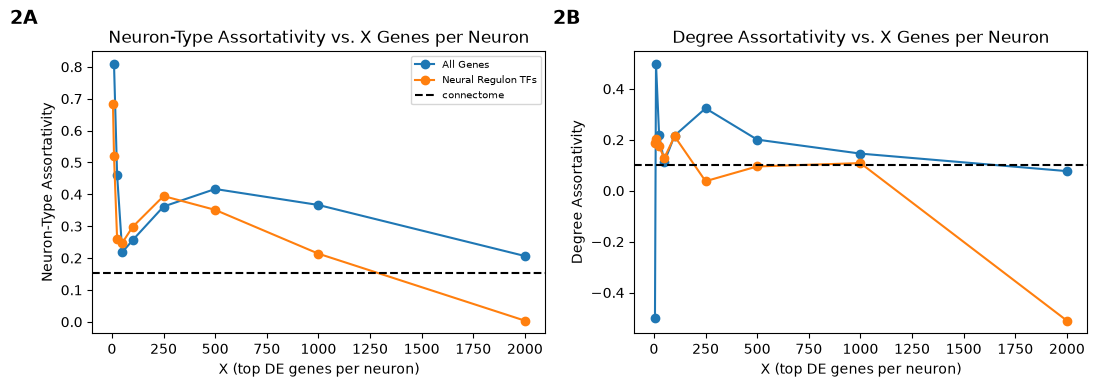

,source,X,n_edges,type_assort,type_assort_p,degree_assort,degree_assort_p
0,connectome,NaN,1474,0.154,0.01,0.100,0.010
1,All Genes,5.0,3,NaN,NaN,-0.500,NaN
2,All Genes,10.0,27,0.809,0.01,0.498,0.010
3,All Genes,25.0,225,0.462,0.01,0.220,0.010
4,All Genes,50.0,1017,0.218,0.01,0.112,0.010
5,All Genes,100.0,1474,0.256,0.01,0.216,0.010
6,All Genes,250.0,1474,0.362,0.01,0.324,0.010
7,All Genes,500.0,1474,0.417,0.01,0.201,0.010
8,All Genes,1000.0,1474,0.367,0.01,0.146,0.010
9,All Genes,2000.0,1474,0.206,0.01,0.077,0.010


In [39]:
a1, nets = analysis1(conn, lfc, types, sources, XS, N_PERM, OUT, SEED)
a1.round(3)

No regulon sets loaded: TFs not drawn. Set REGULON_FILES in the first cell to add them.


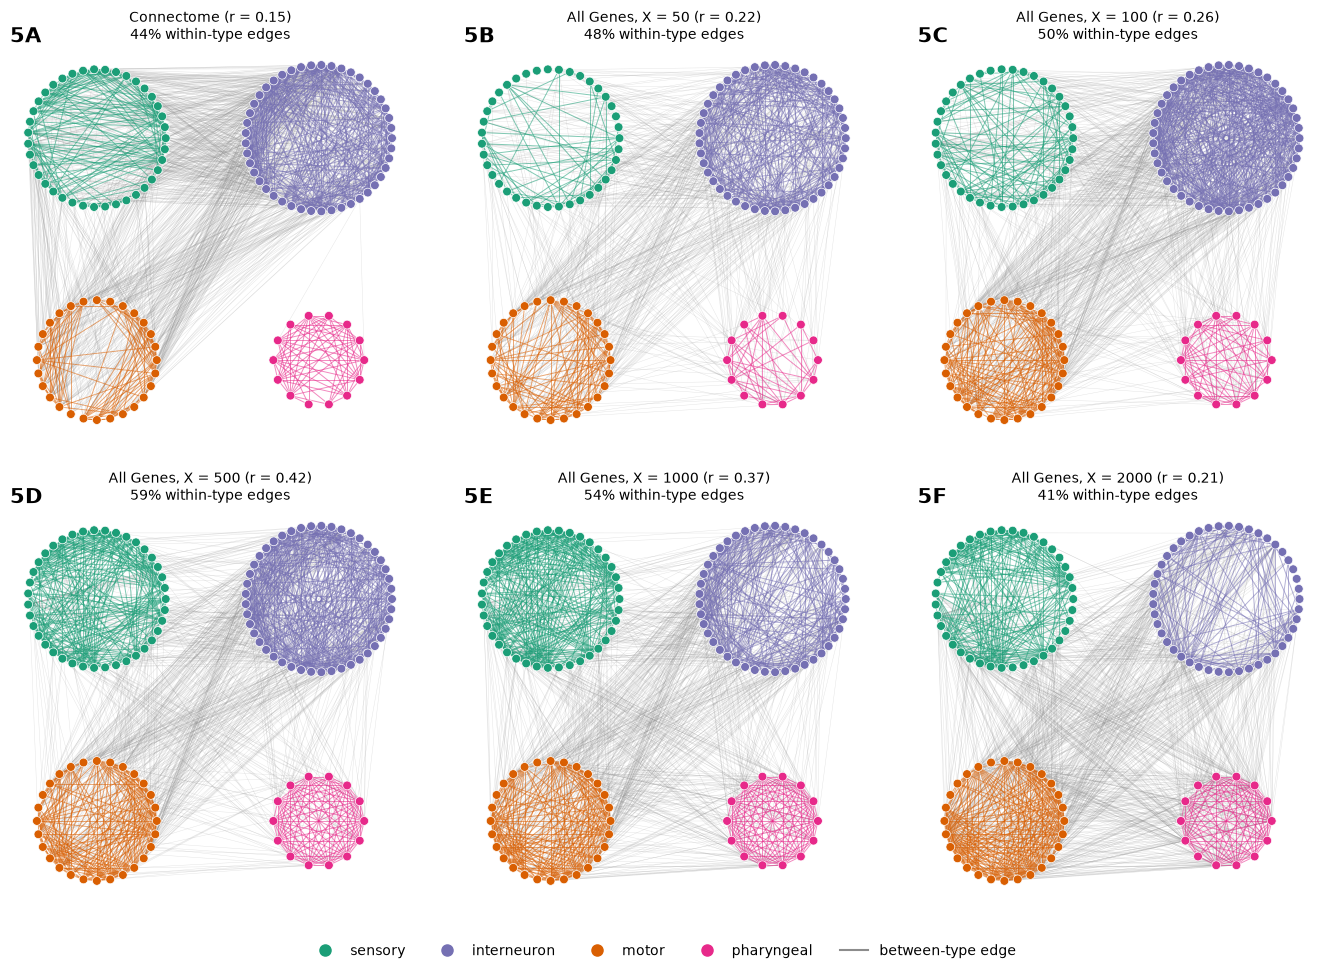

No regulon sets loaded: TFs not drawn. Set REGULON_FILES in the first cell to add them.


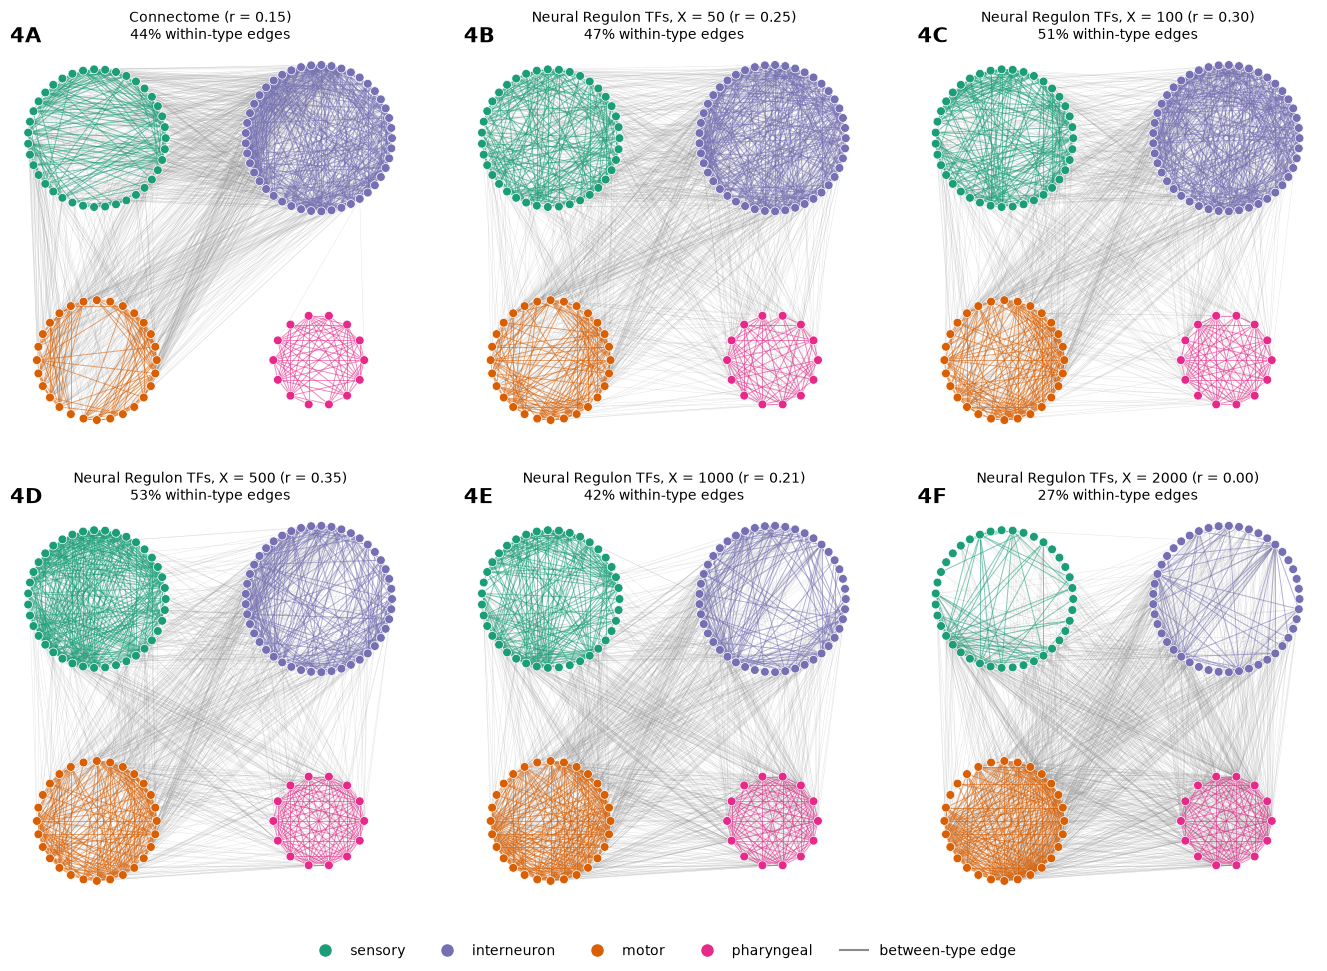

In [50]:
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from scipy.stats import hypergeom

TYPE_COLORS = {"sensory": "#1b9e77", "interneuron": "#7570b3", "motor": "#d95f02", "pharyngeal": "#e7298a"}
TF_COLOR = "#f2c14e"


def _bh_local(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = np.empty_like(p)
    q[o] = np.minimum.accumulate((p[o] * len(p) / (np.arange(len(p)) + 1))[::-1])[::-1]
    return np.minimum(q, 1.0)


def type_layout(types, gap=3.2):
    """Four clusters (one per neuron type); neurons sit on a circle inside their cluster."""
    centers = {"sensory": (-gap, gap), "interneuron": (gap, gap),
               "motor": (-gap, -gap), "pharyngeal": (gap, -gap)}
    pos = {}
    for t, (cx, cy) in centers.items():
        members = sorted(types.index[types == t])
        r = 0.3 + 0.27 * np.sqrt(len(members))
        for i, n in enumerate(members):
            a = 2 * np.pi * i / max(len(members), 1)
            pos[n] = (cx + r * np.cos(a), cy + r * np.sin(a))
    return pos


def tf_neuron_links(sub, reg_sets, X, fdr=0.05, min_overlap=3, n_tf=12):
    """TF-neuron links: TF regulon enriched among a neuron's top-X DE genes (hypergeometric, BH over all tests)."""
    genes = sub.index.values
    N = len(genes)
    Xe = min(X, N)
    top = np.zeros(sub.shape, bool)
    np.put_along_axis(top, np.argsort(-sub.values, axis=0)[:Xe], True, axis=0)   # genes x neurons
    gidx = {g: i for i, g in enumerate(genes)}
    names, cols = [], []
    for key, targets in reg_sets.items():
        idx = [gidx[g] for g in targets if g in gidx]
        if len(idx) >= 5:
            col = np.zeros(N, bool)
            col[idx] = True
            names.append(key.split(":", 1)[-1])
            cols.append(col)
    if not cols:
        return None
    R = np.array(cols).T                                   # genes x TFs
    overlap = R.T.astype(int) @ top.astype(int)            # TFs x neurons
    K = R.sum(0)[:, None]
    p = hypergeom.sf(overlap - 1, N, K, Xe)
    q = _bh_local(p.ravel()).reshape(p.shape)
    sig = (q < fdr) & (overlap >= min_overlap)
    n_sig = sig.sum(1)
    order = [i for i in np.lexsort((q.min(1), -n_sig)) if n_sig[i] > 0][:n_tf]
    if not order:
        return None
    nl = list(sub.columns)
    return {"names": [names[i] for i in order],
            "neurons": [[nl[j] for j in np.where(sig[i])[0]] for i in order]}


def add_tfs(ax, tf, pos, ring=8.2):
    cent = [np.mean([pos[n] for n in ns], axis=0) for ns in tf["neurons"]]
    ang = np.array([np.arctan2(c[1], c[0]) for c in cent])
    order = np.argsort(ang)
    gap = 0.17
    a = ang[order].copy()
    for i in range(1, len(a)):
        a[i] = max(a[i], a[i - 1] + gap)
    pts = {}
    segs = []
    for k, i in enumerate(order):
        p = (ring * np.cos(a[k]), ring * np.sin(a[k]))
        pts[i] = p
        segs += [(p, pos[n]) for n in tf["neurons"][i]]
    ax.add_collection(LineCollection(segs, colors="0.15", linewidths=0.4, alpha=0.25, zorder=1.5))
    for i, p in pts.items():
        ax.scatter([p[0]], [p[1]], marker="D", s=70, color=TF_COLOR, edgecolor="black", linewidth=0.8, zorder=4)
        ax.text(p[0] * 1.07, p[1] * 1.07, tf["names"][i], fontsize=6.5, ha="left" if p[0] >= 0 else "right",
                va="center", zorder=5)
    ax.set_xlim(-10.5, 10.5)
    ax.set_ylim(-9.6, 9.6)


def draw_network(ax, G, pos, types, title, label=None, tf=None):
    between, within = [], {t: [] for t in TYPE_COLORS}
    for u, v in G.edges():
        seg = (pos[u], pos[v])
        if types[u] == types[v]:
            within[types[u]].append(seg)
        else:
            between.append(seg)
    ax.add_collection(LineCollection(between, colors="0.55", linewidths=0.3, alpha=0.25, zorder=1))
    for t, segs in within.items():
        ax.add_collection(LineCollection(segs, colors=TYPE_COLORS[t], linewidths=0.7, alpha=0.55, zorder=2))
    nl = list(G.nodes())
    xy = np.array([pos[n] for n in nl])
    ax.scatter(xy[:, 0], xy[:, 1], c=[TYPE_COLORS[types[n]] for n in nl], s=40,
               edgecolor="white", linewidth=0.5, zorder=3)
    n_within = sum(len(s) for s in within.values())
    total = max(n_within + len(between), 1)
    ax.set_title(f"{title}\n{n_within / total:.0%} within-type edges", fontsize=10)
    ax.autoscale_view()
    if tf is not None:
        add_tfs(ax, tf, pos)
    ax.set_aspect("equal")
    ax.axis("off")
    if label:
        ax.text(0.0, 1.0, label, transform=ax.transAxes, fontsize=15, fontweight="bold",
                va="bottom", ha="left")


def plot_networks(conn, nets, types, res, lfc, sources, reg_sets=None, source="all_genes",
                  Xs=(100, 500, 2000), fig_no=3, n_tf=12, ncols=None, out=None):
    avail = sorted(X for (s, X) in nets if s == source)
    if not avail:
        raise ValueError(f"No networks built for source '{source}'. Sources with networks: "
                         f"{sorted({s for s, _ in nets})}")
    Xs = [X for X in Xs if (source, X) in nets]
    if not Xs:
        Xs = [avail[i] for i in sorted({0, len(avail) // 2, len(avail) - 1})]
        print(f"Requested X values not in nets for '{source}'; using available X = {Xs}")
    use_tf = bool(reg_sets)
    if not use_tf:
        print("No regulon sets loaded: TFs not drawn. Set REGULON_FILES in the first cell to add them.")
    pos = type_layout(types)
    letters = "ABCDEFGHIJ"

    n_panels = 1 + len(Xs)                                   # connectome + one panel per X
    nrows = 1 if n_panels <= 3 else 2
    ncols = ncols or int(np.ceil(n_panels / nrows))          # ceil, so an odd panel count is not dropped
    side = 5.6 if use_tf else 4.6                            # inches per panel
    # figure height must scale with the number of rows: the panels are equal-aspect squares, so a
    # figure that is too short for its rows shrinks them and leaves large gaps between columns
    fig, axes = plt.subplots(nrows, ncols, figsize=(side * ncols, side * nrows + 0.7), squeeze=False)
    axes = axes.flatten()
    for ax in axes[n_panels:]:
        ax.axis("off")                                       # hide unused cells in the grid

    r0 = res.loc[res.source == "connectome", "type_assort"].iloc[0]
    draw_network(axes[0], conn, pos, types, f"Connectome (r = {r0:.2f})", label=f"{fig_no}{letters[0]}")
    if use_tf:                       # same extent as the TF panels so all panels are drawn at one scale
        axes[0].set_xlim(-10.5, 10.5)
        axes[0].set_ylim(-9.6, 9.6)
    genes = sources.get(source)
    sub = lfc if genes is None else lfc.loc[lfc.index.intersection(list(genes))]
    for k, (ax, X) in enumerate(zip(axes[1:n_panels], Xs), start=1):
        G = nets[(source, X)][0]
        r = res.loc[(res.source == source) & (res.X == X), "type_assort"].iloc[0]
        tf = tf_neuron_links(sub, reg_sets, X, n_tf=n_tf) if use_tf else None
        if use_tf and tf is None:
            print(f"X = {X}: no TF regulon significantly enriched in any neuron's top-X genes")
        draw_network(ax, G, pos, types, f"{source}, X = {X} (r = {r:.2f})",
                     label=f"{fig_no}{letters[k]}", tf=tf)

    handles = [Line2D([0], [0], marker="o", ls="", color=c, label=t, markersize=8) for t, c in TYPE_COLORS.items()]
    handles.append(Line2D([0], [0], color="0.55", label="between-type edge"))
    if use_tf:
        handles += [Line2D([0], [0], marker="D", ls="", color=TF_COLOR, markeredgecolor="black",
                           label="transcription factor", markersize=8),
                    Line2D([0], [0], color="0.15", alpha=0.4, label="TF regulon enriched in neuron")]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False)
    # one layout call only: tight_layout() would override subplots_adjust(), so use subplots_adjust alone
    fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.07, hspace=0.18, wspace=0.02)
    if out is not None:
        fig.savefig(Path(out) / f"analysis1_network_visualization_{fig_no}.png", dpi=200, bbox_inches="tight")
    plt.show()


plot_networks(conn, nets, types, a1, lfc, sources, reg_sets=None, source="All Genes",
              Xs=(50, 100, 500, 1000, 2000), fig_no=5, n_tf=12, out=OUT)

plot_networks(conn, nets, types, a1, lfc, sources, reg_sets=None, source="Neural Regulon TFs",
              Xs=(50, 100, 500, 1000, 2000), fig_no=4, n_tf=12, out=OUT)